# **Аналітика опитування щодо спільного вибору фільмів**

In [11]:
from pathlib import Path

# Знаходимо корінь репозиторію за README.md
current_dir = Path.cwd()
project_root = next(
    (path for path in [current_dir, *current_dir.parents] if (path / 'README.md').exists()),
    current_dir
)

data_path = project_root / 'data' / 'survey.xlsx'
output_path = project_root / 'survey' / 'outputs'
output_path.mkdir(parents=True, exist_ok=True)

print(f'Корінь проєкту: {project_root}')
print(f'Файл даних: {data_path}')
print(f'Папка експорту: {output_path}')

Корінь проєкту: c:\Users\ACER\github\analytics
Файл даних: c:\Users\ACER\github\analytics\data\survey.xlsx
Папка експорту: c:\Users\ACER\github\analytics\survey\outputs


In [49]:
# Імпорт бібліотек для аналізу даних та побудови візуалізацій
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [50]:
# Завантаження даних опитування з локального Excel-файлу та перегляд перших 5 рядків
if not data_path.exists():
    raise FileNotFoundError(
        f'Не знайдено файл опитування: {data_path}\n'
        'Покладіть survey.xlsx у папку data/ в корені репозиторію.'
    )

df = pd.read_excel(data_path)

df.head()

,Позначка часу,Які функції застосунку для спільного вибору фільмів були б для вас найкориснішими?,"1. Як часто ти дивишся фільми разом із друзями, партнером або родиною?",2. Як ви зазвичай обираєте фільм для спільного перегляду?,Що найчастіше ускладнює вибір фільму?,Скільки часу зазвичай займає вибір фільму?,Що могло б допомогти вашій компанії швидше обирати фільм?
0,2026-10-17 19:04:09.277,NaN,Рідше,Разом шукаємо фільм на різних платформах,"Важко знайти фільм, який усім сподобається, Ви...",15–30 хвилин,"Спільне голосування за фільми, Підбір фільмів ..."
1,2026-10-17 19:04:26.508,NaN,Приблизно раз на тиждень,Разом шукаємо фільм на різних платформах,"Важко знайти фільм, який усім сподобається, Ви...",15–30 хвилин,"Спільне голосування за фільми, Підбір фільмів ..."
2,2026-10-17 19:07:57.699,NaN,Приблизно раз на тиждень,Обирає одна людина,"Важко знайти фільм, який усім сподобається",5–15 хвилин,"Спільне голосування за фільми, Спільний список..."
3,2026-10-17 19:08:34.561,NaN,Приблизно раз на тиждень,Разом шукаємо фільм на різних платформах,Витрачаємо багато часу на пошук,5–15 хвилин,"Фільтри за жанром, рейтингом і роком випуску"
4,2026-10-17 19:11:21.350,NaN,Рідше,Разом шукаємо фільм на різних платформах,"Важко знайти фільм, який усім сподобається, За...",5–15 хвилин,"Фільтри за жанром, рейтингом і роком випуску"


## **1. Перевірка та очищення даних**

In [51]:
# Перевірка кількості рядків і стовпців у наборі даних
df.shape

(50, 7)

In [52]:
# Перевірка типів даних, кількості заповнених значень і структури таблиці
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column                                                                              Non-Null Count  Dtype         
---  ------                                                                              --------------  -----         
 0   Позначка часу                                                                       50 non-null     datetime64[ns]
 1   Які функції застосунку для спільного вибору фільмів були б для вас найкориснішими?  22 non-null     object        
 2   1. Як часто ти дивишся фільми разом із друзями, партнером або родиною?              50 non-null     object        
 3   2. Як ви зазвичай обираєте фільм для спільного перегляду?                           50 non-null     object        
 4   Що найчастіше ускладнює вибір фільму?                                               50 non-null     object        
 5   Скільки часу зазвичай займає вибір фільму?           

In [53]:
# Перейменування стовпців для зручності подальшого аналізу
df = df.rename(columns={
    'Позначка часу': 'timestamp',
    'Які функції застосунку для спільного вибору фільмів були б для вас найкориснішими?': 'useful_features',
    '1. Як часто ти дивишся фільми разом із друзями, партнером або родиною?': 'watch_frequency',
    '2. Як ви зазвичай обираєте фільм для спільного перегляду?': 'selection_method',
    'Що найчастіше ускладнює вибір фільму?': 'selection_difficulty',
    'Скільки часу зазвичай займає вибір фільму?': 'selection_time',
    'Що могло б допомогти вашій компанії швидше обирати фільм?': 'helpful_solutions'
})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   timestamp             50 non-null     datetime64[ns]
 1   useful_features       22 non-null     object        
 2   watch_frequency       50 non-null     object        
 3   selection_method      50 non-null     object        
 4   selection_difficulty  50 non-null     object        
 5   selection_time        50 non-null     object        
 6   helpful_solutions     50 non-null     object        
dtypes: datetime64[ns](1), object(6)
memory usage: 2.9+ KB


In [54]:
# Перевірка кількості пропущених значень у кожному стовпці
df.isna().sum()

timestamp                0
useful_features         28
watch_frequency          0
selection_method         0
selection_difficulty     0
selection_time           0
helpful_solutions        0
dtype: int64

In [55]:
# Заповнення пропущених значень у стовпці useful_features
df['useful_features'] = df['useful_features'].fillna('Утрималися від відповіді')

## **2. Дослідницький аналіз даних та візуалізація**

In [56]:
# Визначення дати першої відповіді на опитування
df['timestamp'].min()

Timestamp('2026-10-17 19:04:09.277000')

In [57]:
# Визначення дати останньої відповіді на опитування
df['timestamp'].max()

Timestamp('2026-10-22 15:40:12.793000')

In [58]:
# Визначення кількості календарних днів, у які надходили відповіді
df['timestamp'].dt.date.nunique()

5

In [59]:
# Формування таблиці з кількістю відповідей за кожен день
daily_responses = (df.groupby(df['timestamp'].dt.date).size().reset_index(name='Кількість відповідей'))
daily_responses = daily_responses.rename(columns={'timestamp': 'Дата'})

daily_responses

,Дата,Кількість відповідей
0,2026-10-17,34
1,2026-10-18,9
2,2026-10-19,4
3,2026-10-21,2
4,2026-10-22,1


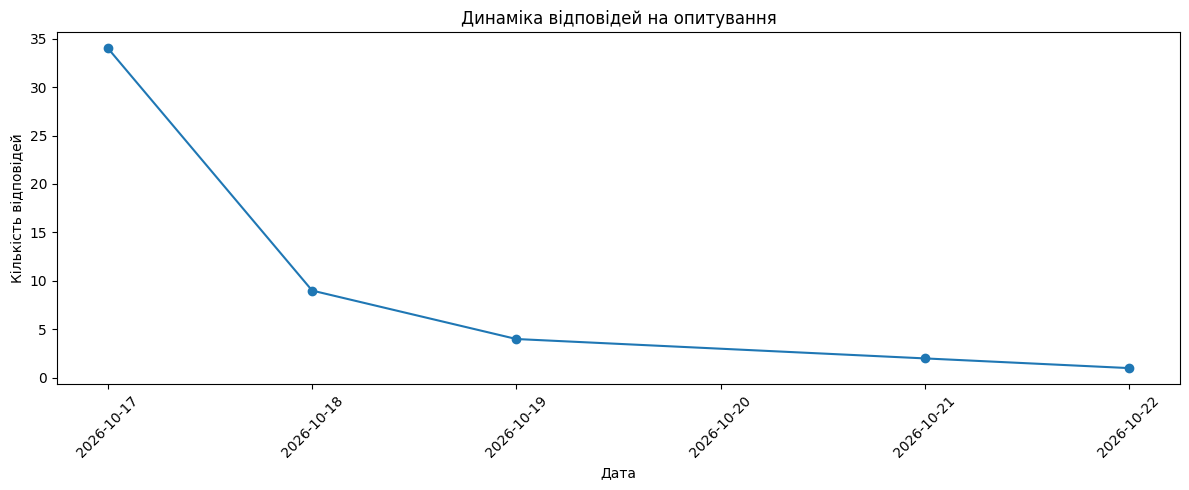

In [60]:
# Побудова та оформлення лінійної діаграми динаміки відповідей на опитування
daily_responses.plot(
    x='Дата',
    y='Кількість відповідей',
    kind='line',
    marker='o',
    figsize=(12, 5),
    legend=False
)

plt.title('Динаміка відповідей на опитування')
plt.xlabel('Дата')
plt.ylabel('Кількість відповідей')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [61]:
# Очищення та розділення відповідей на окремі варіанти
features = (
    df['useful_features']
    .str.replace(
        'Фільтрувати фільми за жанром, тривалістю та іншими параметрами',
        'Фільтрувати фільми за жанром тривалістю та іншими параметрами',
        regex=False
    )
    .str.replace(
        'Знаходити фільми, доступні на потрібному стримінговому сервісі',
        'Знаходити фільми доступні на потрібному стримінговому сервісі',
        regex=False
    )
    .str.split(', ')
    .explode()
)

features_summary = features.value_counts()

features_summary

useful_features
Утрималися від відповіді                                         28
Отримувати рекомендації на основі спільних інтересів             16
Оцінювати фільми незалежно одне від одного та знаходити збіги    11
Створювати спільний список фільмів і голосувати за них           11
Фільтрувати фільми за жанром тривалістю та іншими параметрами     9
Знаходити фільми доступні на потрібному стримінговому сервісі     7
Жодна із цих функцій                                              1
Name: count, dtype: int64

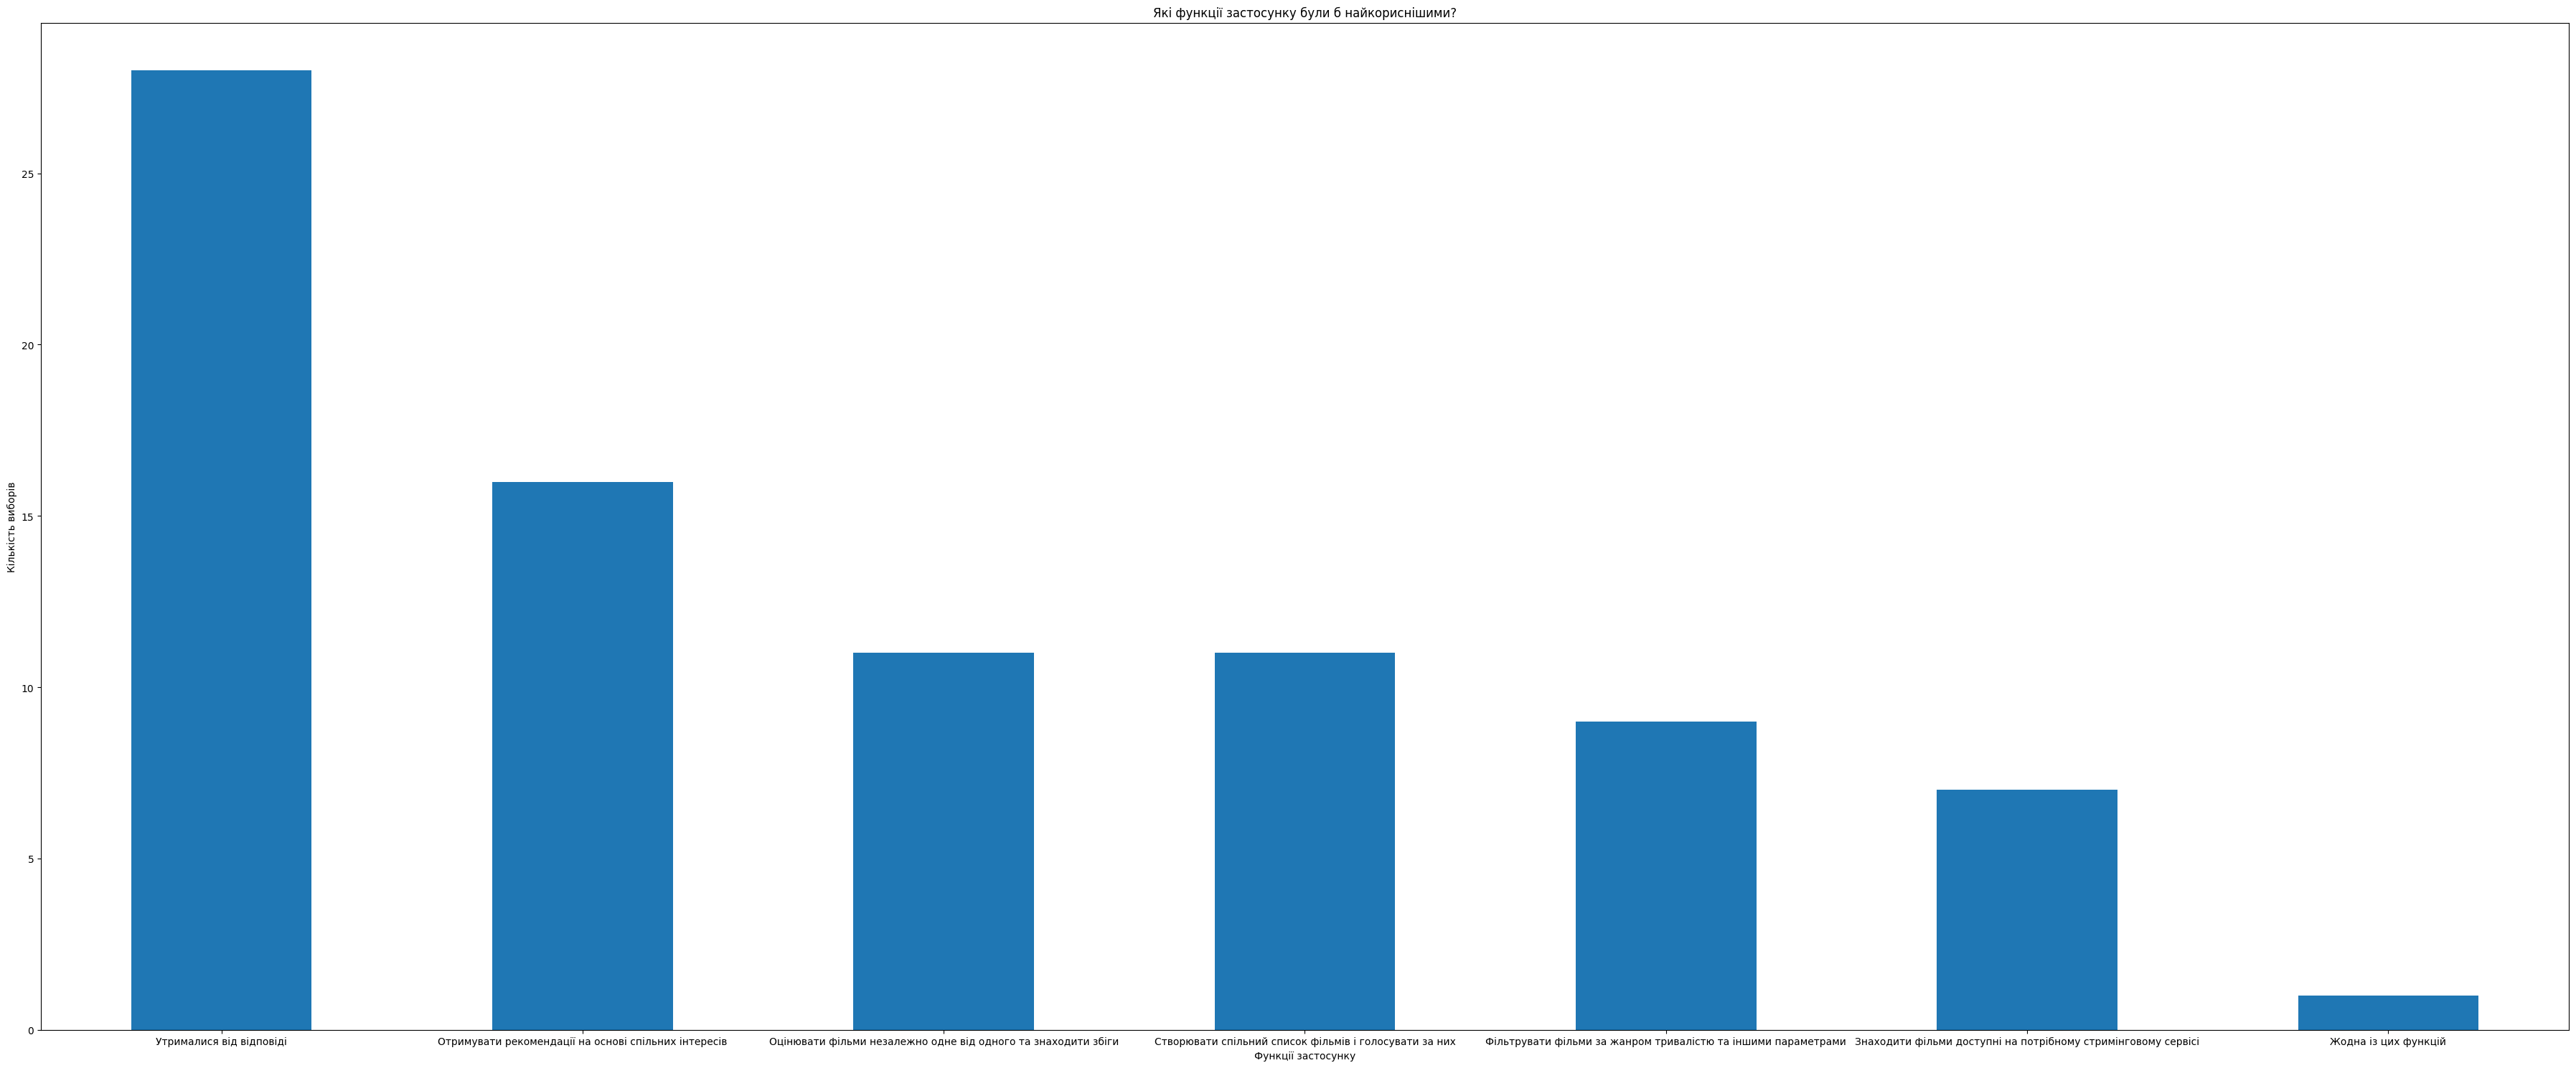

In [62]:
# Побудова та оформлення стовпчикової діаграми корисних функцій застосунку
features_summary.plot(kind='bar', figsize=(36, 15))

plt.title('Які функції застосунку були б найкориснішими?')
plt.xlabel('Функції застосунку')
plt.ylabel('Кількість виборів')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [63]:
# Підрахунок кількості відповідей для кожного варіанта частоти спільного перегляду фільмів
watch_frequency_summary = df['watch_frequency'].value_counts()

watch_frequency_summary

watch_frequency
Приблизно раз на тиждень    12
Кілька разів на тиждень     12
Кілька разів на місяць      12
Рідше                        8
Майже ніколи                 6
Name: count, dtype: int64

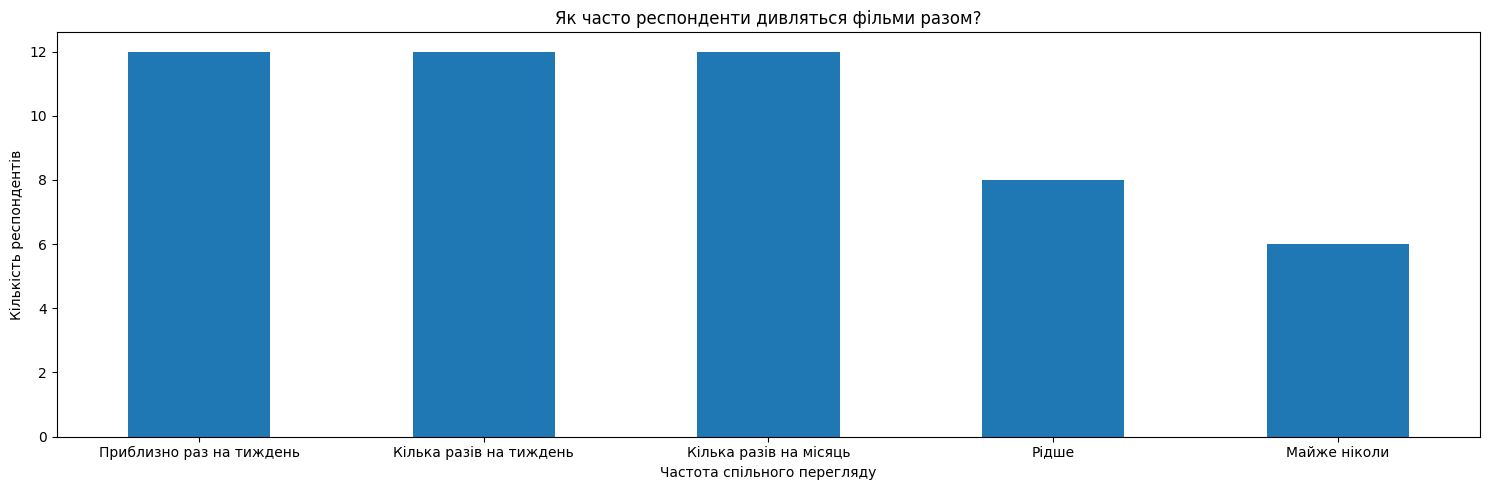

In [64]:
# Побудова та оформлення стовпчикової діаграми частоти спільного перегляду фільмів
watch_frequency_summary.plot(kind='bar', figsize=(15, 5))

plt.title('Як часто респонденти дивляться фільми разом?')
plt.xlabel('Частота спільного перегляду')
plt.ylabel('Кількість респондентів')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [65]:
# Підрахунок кількості відповідей для кожного способу вибору фільму
method_summary = df['selection_method'].value_counts()

method_summary

selection_method
Разом шукаємо фільм на різних платформах            20
По черзі пропонуємо варіанти                        13
Обирає одна людина                                   7
Довго обговорюємо, поки не домовимося                6
Голосуємо за запропоновані варіанти                  2
Дивимось відгуки і обираємо                          1
відкриваємо список IMBD і по черзі все дивимось      1
Name: count, dtype: int64

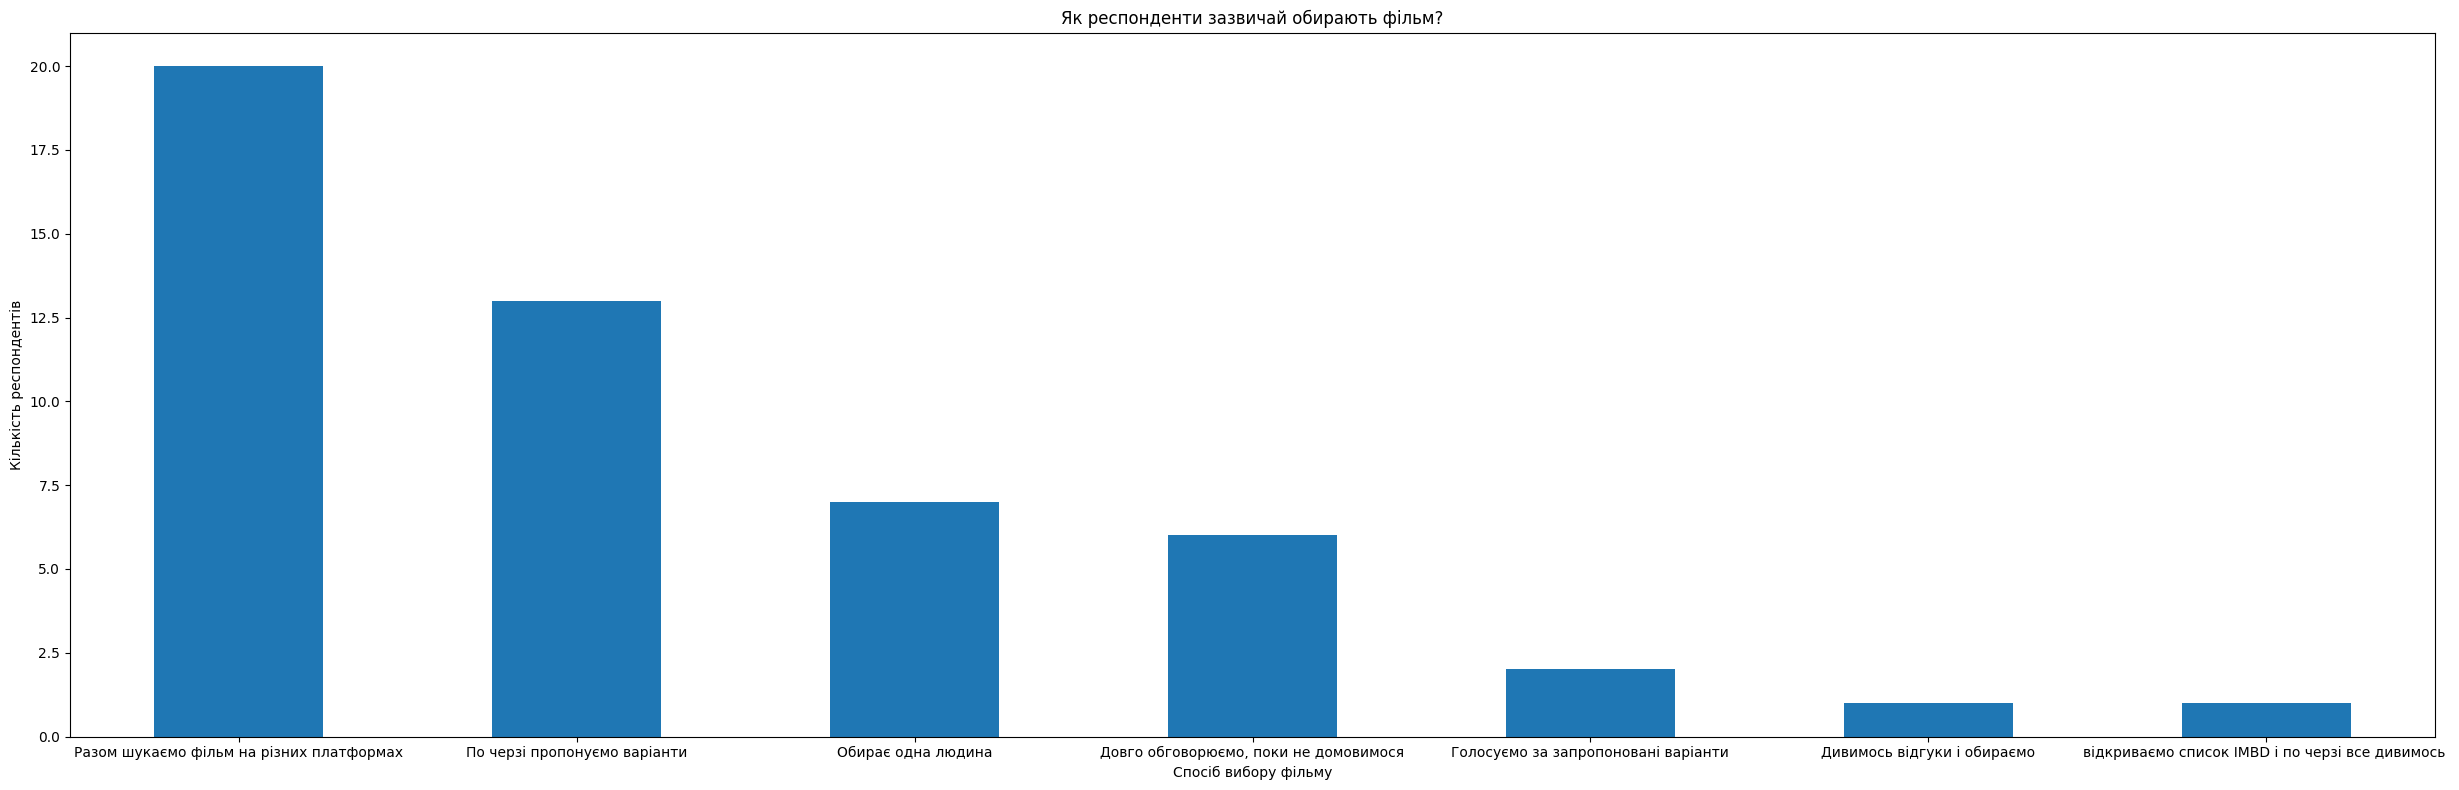

In [66]:
# Побудова та оформлення стовпчикової діаграми способів вибору фільму
method_summary.plot(kind='bar', figsize=(25, 8))

plt.title('Як респонденти зазвичай обирають фільм?')
plt.xlabel('Спосіб вибору фільму')
plt.ylabel('Кількість респондентів')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [67]:
# Очищення, розділення та підрахунок відповідей про труднощі під час вибору фільму
difficulty = (
    df['selection_difficulty']
    .str.replace(
        'Важко знайти фільм, який усім сподобається',
        'Важко знайти фільм який усім сподобається',
        regex=False
    )
    .str.split(', ')
    .explode()
)

difficulty_counts = difficulty.value_counts()

difficulty_counts

selection_difficulty
Важко знайти фільм який усім сподобається    31
Витрачаємо багато часу на пошук              24
У всіх різні смаки                           17
Забагато варіантів                           10
складно визначитися                          10
Не можемо домовитися                          9
Зазвичай проблем із вибором немає             8
Багато фільмів бачили                         1
Name: count, dtype: int64

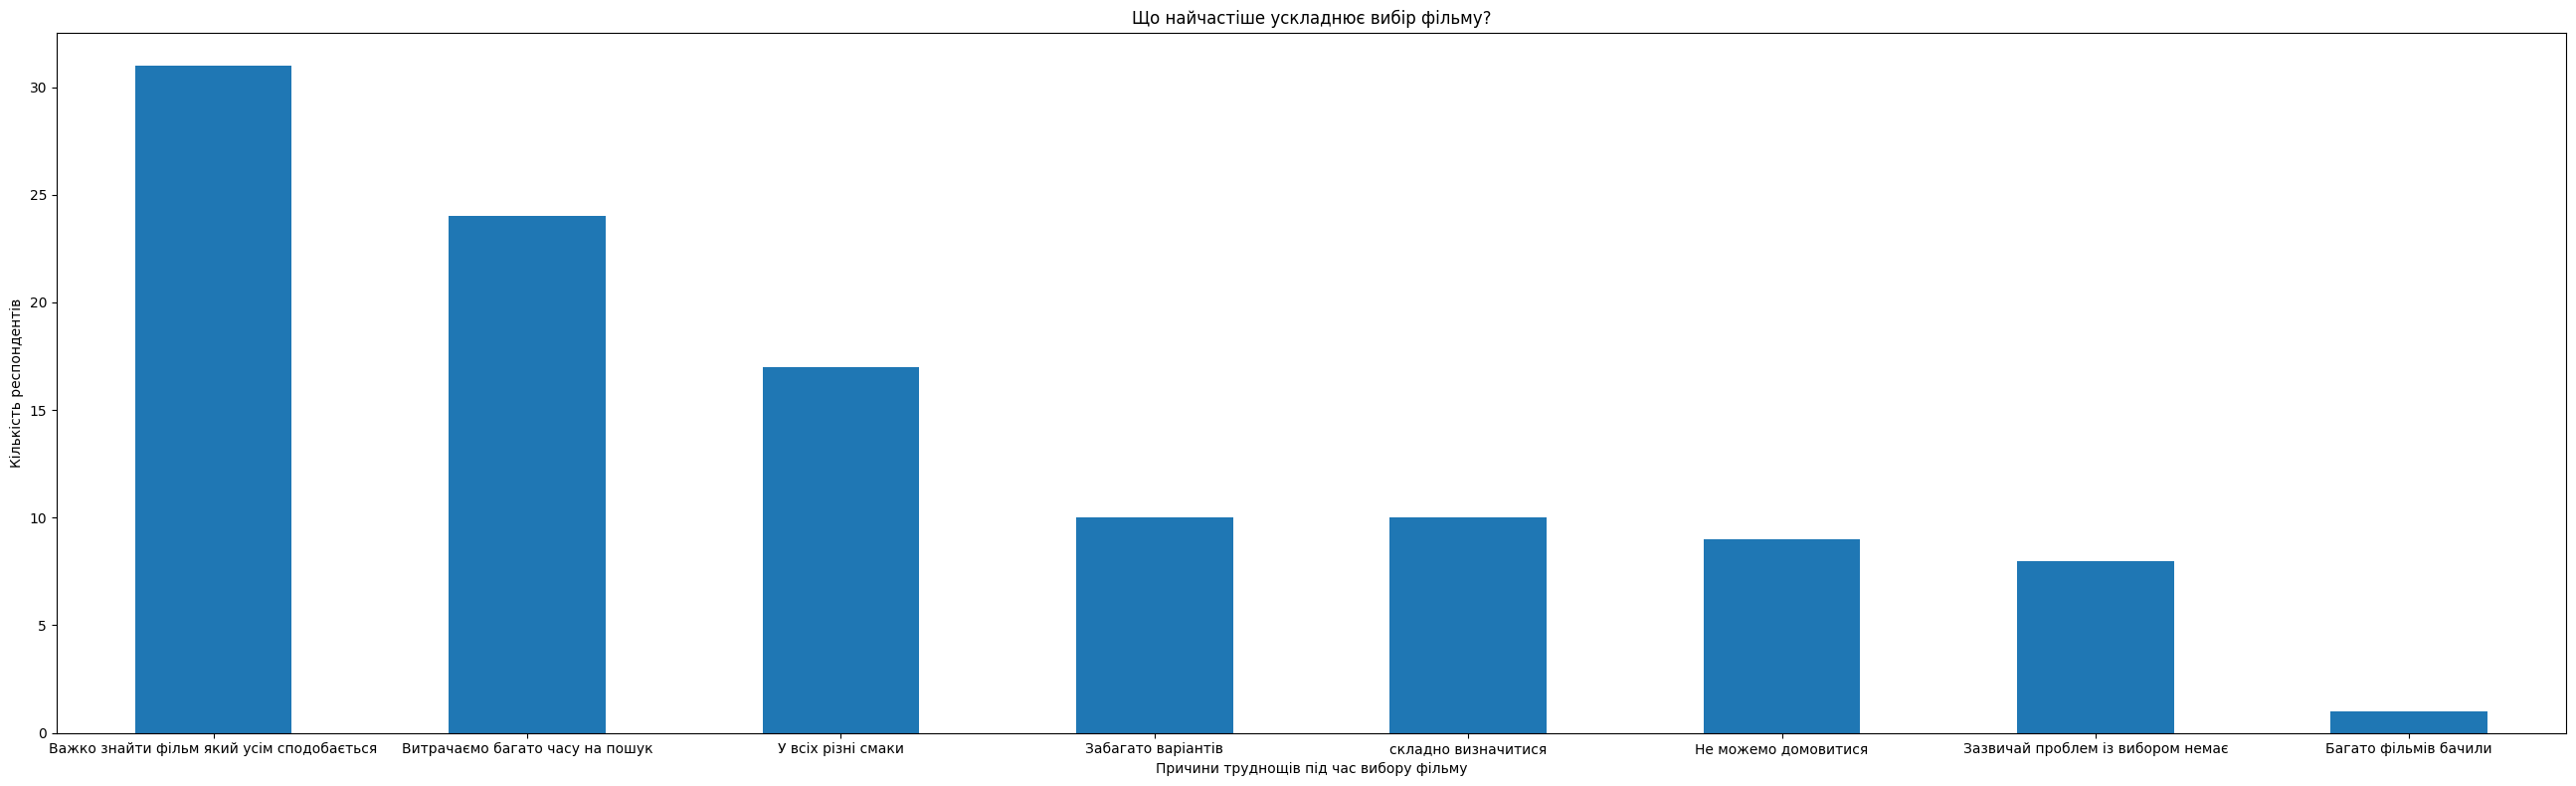

In [68]:
# Побудова та оформлення стовпчикової діаграми труднощів під час вибору фільму
difficulty_counts.plot(kind='bar', figsize=(26, 8))

plt.title('Що найчастіше ускладнює вибір фільму?')
plt.xlabel('Причини труднощів під час вибору фільму')
plt.ylabel('Кількість респондентів')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [69]:
# Підрахунок кількості відповідей для кожного варіанта часу, необхідного для вибору фільму
time_summary = df['selection_time'].value_counts()

time_summary

selection_time
5–15 хвилин        24
15–30 хвилин       21
Понад 30 хвилин     3
До 5 хвилин         2
Name: count, dtype: int64

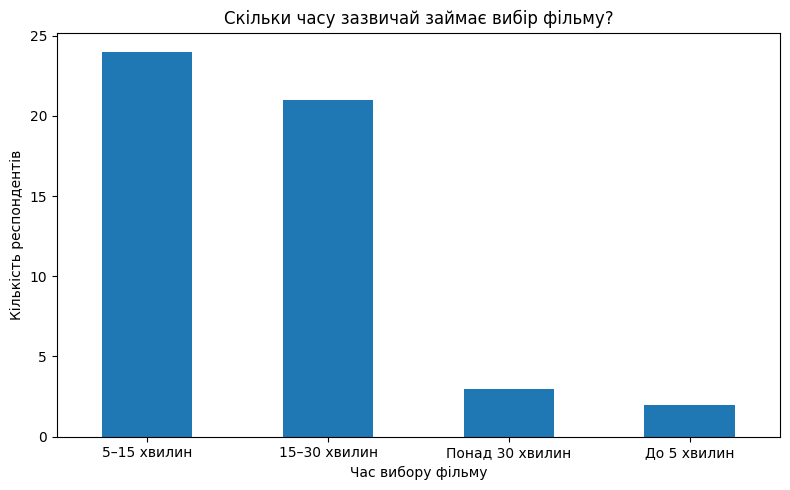

In [70]:
# Побудова та оформлення стовпчикової діаграми часу, необхідного для вибору фільму
time_summary.plot(kind='bar', figsize=(8, 5))

plt.title('Скільки часу зазвичай займає вибір фільму?')
plt.xlabel('Час вибору фільму')
plt.ylabel('Кількість респондентів')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [71]:
# Очищення, розділення та підрахунок відповідей щодо рішень для швидшого вибору фільму
solutions = (
    df['helpful_solutions']
    .str.replace(
        'Спільний список фільмів, які хочемо подивитися',
        'Спільний список фільмів які хочемо подивитися',
        regex=False
    )
    .str.replace(
        'Фільтри за жанром, рейтингом і роком випуску',
        'Фільтри за жанром рейтингом і роком випуску',
        regex=False
    )
    .str.split(', ')
    .explode()
)

solutions_summary = solutions.value_counts()

solutions_summary

helpful_solutions
Підбір фільмів за вподобаннями всіх учасників    31
Спільний список фільмів які хочемо подивитися    22
Спільне голосування за фільми                    18
Фільтри за жанром рейтингом і роком випуску      18
Випадковий вибір фільму                          12
Name: count, dtype: int64

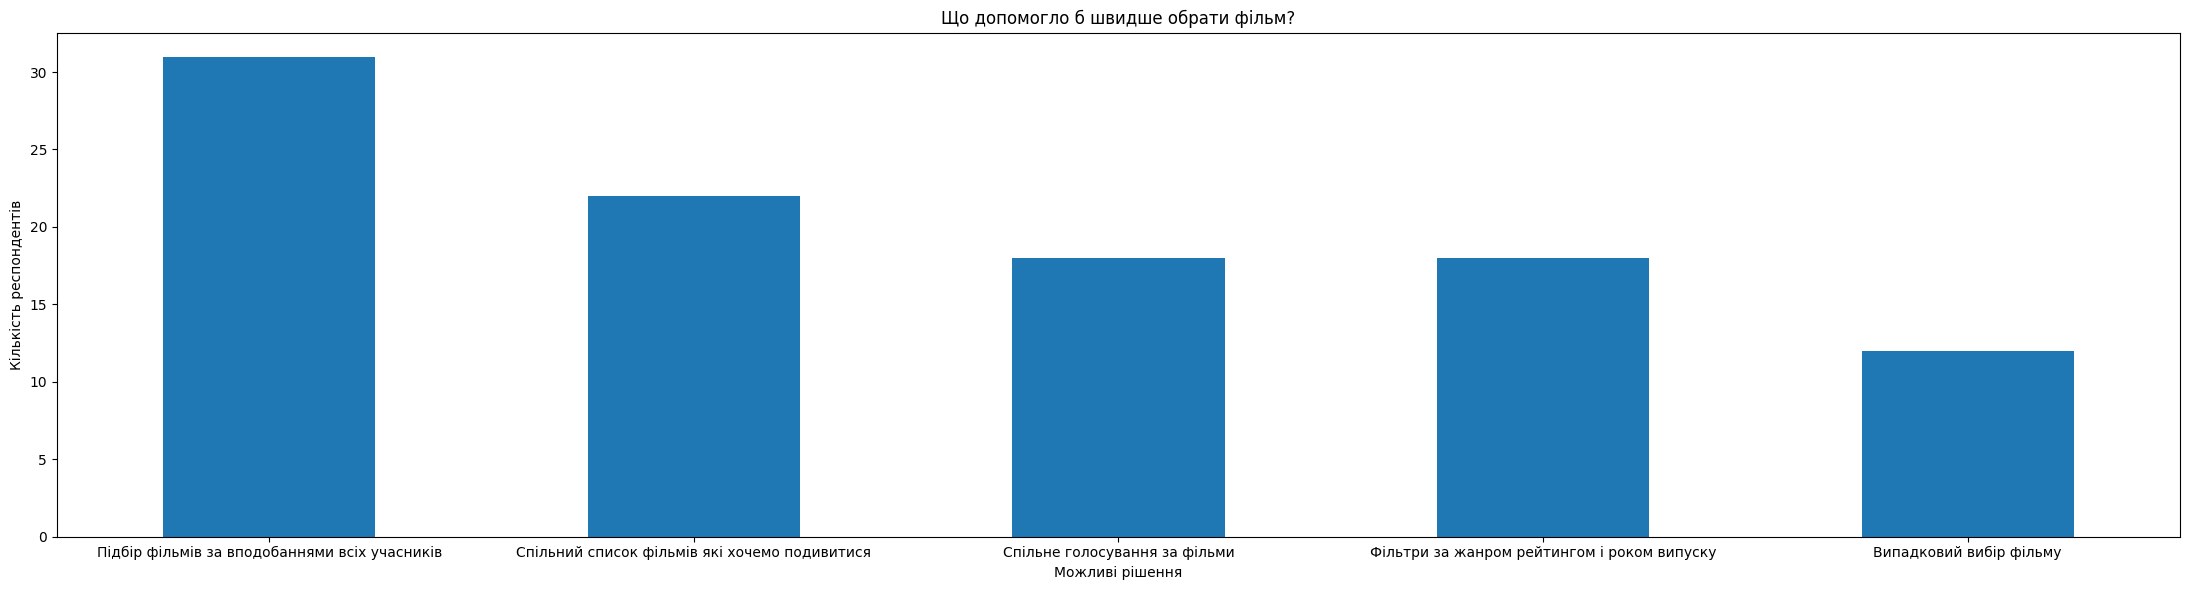

In [72]:
# Побудова та оформлення стовпчикової діаграми рішень для швидшого вибору фільму
solutions_summary.plot(kind='bar', figsize=(22, 6))

plt.title('Що допомогло б швидше обрати фільм?')
plt.xlabel('Можливі рішення')
plt.ylabel('Кількість респондентів')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **3. Підготовка даних для Tableau**

In [73]:
# Формування таблиці частоти спільного перегляду фільмів
watch_frequency_table = (
    watch_frequency_summary
    .rename_axis('Частота спільного перегляду')
    .reset_index(name='Кількість респондентів')
)

watch_frequency_table

,Частота спільного перегляду,Кількість респондентів
0,Приблизно раз на тиждень,12
1,Кілька разів на тиждень,12
2,Кілька разів на місяць,12
3,Рідше,8
4,Майже ніколи,6


In [74]:
# Формування таблиці способів вибору фільму
method_table = (
    method_summary
    .rename_axis('Спосіб вибору фільму')
    .reset_index(name='Кількість респондентів')
)

method_table

,Спосіб вибору фільму,Кількість респондентів
0,Разом шукаємо фільм на різних платформах,20
1,По черзі пропонуємо варіанти,13
2,Обирає одна людина,7
3,"Довго обговорюємо, поки не домовимося",6
4,Голосуємо за запропоновані варіанти,2
5,Дивимось відгуки і обираємо,1
6,відкриваємо список IMBD і по черзі все дивимось,1


In [75]:
# Формування таблиці часу, необхідного для вибору фільму
time_table = (
    time_summary
    .rename_axis('Час вибору фільму')
    .reset_index(name='Кількість респондентів')
)

time_table

,Час вибору фільму,Кількість респондентів
0,5–15 хвилин,24
1,15–30 хвилин,21
2,Понад 30 хвилин,3
3,До 5 хвилин,2


In [76]:
# Формування таблиці труднощів під час вибору фільму
difficulty_table = (
    difficulty_counts
    .rename_axis('Причина труднощів')
    .reset_index(name='Кількість виборів')
)

difficulty_table

,Причина труднощів,Кількість виборів
0,Важко знайти фільм який усім сподобається,31
1,Витрачаємо багато часу на пошук,24
2,У всіх різні смаки,17
3,Забагато варіантів,10
4,складно визначитися,10
5,Не можемо домовитися,9
6,Зазвичай проблем із вибором немає,8
7,Багато фільмів бачили,1


In [77]:
# Формування таблиці рішень для швидшого вибору фільму
solutions_table = (
    solutions_summary
    .rename_axis('Можливе рішення')
    .reset_index(name='Кількість виборів')
)

solutions_table

,Можливе рішення,Кількість виборів
0,Підбір фільмів за вподобаннями всіх учасників,31
1,Спільний список фільмів які хочемо подивитися,22
2,Спільне голосування за фільми,18
3,Фільтри за жанром рейтингом і роком випуску,18
4,Випадковий вибір фільму,12


In [78]:
# Формування таблиці корисних функцій застосунку
features_table = (
    features_summary
    .rename_axis('Функція застосунку')
    .reset_index(name='Кількість виборів')
)

features_table

,Функція застосунку,Кількість виборів
0,Утрималися від відповіді,28
1,Отримувати рекомендації на основі спільних інт...,16
2,Оцінювати фільми незалежно одне від одного та ...,11
3,Створювати спільний список фільмів і голосуват...,11
4,Фільтрувати фільми за жанром тривалістю та інш...,9
5,Знаходити фільми доступні на потрібному стримі...,7
6,Жодна із цих функцій,1


## **Экспорт таблиць у CSV**

In [79]:
output_path = Path(output_path)
output_path = project_root / 'survey' / 'outputs'
output_path.mkdir(parents=True, exist_ok=True)

# Об'єднуємо підготовлені таблиці в один формат
tables = {
    'watch_frequency': watch_frequency_table,
    'selection_method': method_table,
    'selection_time': time_table,
    'selection_difficulty': difficulty_table,
    'helpful_solutions': solutions_table,
    'useful_features': features_table,
    'daily_responses': daily_responses
}

combined_tables = []

for table_name, table in tables.items():
    temp = table.copy()

    # Зберігаємо назву початкової таблиці
    temp.insert(0, 'Тип аналізу', table_name)

    # Уніфікуємо назви стовпців
    temp.columns = [
        'Тип аналізу' if i == 0 else f'Поле_{i}'
        for i in range(len(temp.columns))
    ]

    combined_tables.append(temp)

# Об'єднуємо всі рядки
tableau_data = pd.concat(
    combined_tables,
    ignore_index=True,
    sort=False
)

# Експорт єдиного файлу
tableau_data.to_csv(
    output_path / 'tableau_all_data.csv',
    index=False,
    encoding='utf-8-sig',
    sep=';'
)

print('Файл створено:', output_path / 'tableau_all_data.csv')
print('Розмір таблиці:', tableau_data.shape)

display(tableau_data.head(10))

Файл створено: c:\Users\ACER\github\analytics\survey\outputs\tableau_all_data.csv
Розмір таблиці: (41, 3)


,Тип аналізу,Поле_1,Поле_2
0,watch_frequency,Приблизно раз на тиждень,12
1,watch_frequency,Кілька разів на тиждень,12
2,watch_frequency,Кілька разів на місяць,12
3,watch_frequency,Рідше,8
4,watch_frequency,Майже ніколи,6
5,selection_method,Разом шукаємо фільм на різних платформах,20
6,selection_method,По черзі пропонуємо варіанти,13
7,selection_method,Обирає одна людина,7
8,selection_method,"Довго обговорюємо, поки не домовимося",6
9,selection_method,Голосуємо за запропоновані варіанти,2
